In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2 qiskit-ibm-runtime==0.50.0


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

# 05 · How does our charging plan survive a noisy quantum chip?

**Motivation.** Notebooks 01–04 use a perfect simulator. Real quantum chips make errors on every gate and every measurement, so a circuit that looks great in simulation can return mostly rule-breaking schedules. Before spending real hardware time we want to know which circuit design holds up best.

**Workflow.**
1. Optimise the QAOA angles on the perfect simulator for three designs: XY mixer + basis start, XY mixer + Dicke start, and the plain X mixer with a penalty term.
2. Compile each circuit for IBM's 156-qubit *Fez* processor layout and count the two-qubit gates.
3. Run 4096 shots on `FakeFez`, a simulator that copies Fez's measured error rates.
4. Score: share of valid schedules, chance of the optimal plan (raw and after discarding invalid shots), approximation ratio, and how close the noisy output is to the perfect one (Hellinger fidelity).
5. Try two cheap fixes: discarding invalid shots and correcting measurement errors.
6. Sweep the error rate of a generic device to see where each design breaks down.

In [3]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez
from evqaoa import DEPOT, qaoa_circuit, output_distribution
from experiments.noise import (setup, best_angles, transpile_for, circuit_stats, sample,
                               score, keep_valid, hellinger_fidelity, calibrate_readout,
                               correct_readout, measured_physical_qubits,
                               depolarizing_model, generic_transpile)

OUT = ROOT / 'results' / '05_noise'; OUT.mkdir(parents=True, exist_ok=True)
SHOTS, PENALTY, REPS = 4096, 1.5, (1, 2, 3)
model, H_plain, base = setup()
_, H_pen, _ = setup(penalty=PENALTY)
RANDOM_VALID = base.n_valid / 2 ** DEPOT.n_qubits
print(f'{base.n_valid} valid schedules of {2**DEPOT.n_qubits}; random 12-bit guess is valid '
      f'{RANDOM_VALID:.1%} of the time | optimum {base.best:.4f}, worst valid {base.worst:.4f}')
CONFIGS = {'XY + basis': ('xy', 'basis', H_plain), 'XY + Dicke': ('xy', 'dicke', H_plain),
           f'X + penalty {PENALTY}': ('x', 'hadamard', H_pen)}

144 valid schedules of 4096; random 12-bit guess is valid 3.5% of the time | optimum 0.5695, worst valid 0.9250


## Step 1 · Optimise angles on the perfect simulator
Each design and depth p gets its own angles (COBYLA, 3 restarts, fixed seed). The X-mixer design is optimised with the penalty in its Hamiltonian, but every design is **scored with the same penalty-free cost**.

In [4]:
t0 = time.time()
circuits, angles, ideal = {}, {}, {}
for name, (mixer, start, H) in CONFIGS.items():
    for p in REPS:
        circ = qaoa_circuit(DEPOT, H, reps=p, mixer=mixer, start=start)
        theta = best_angles(circ, H, seed=p)
        circuits[name, p], angles[name, p] = circ, theta
        ideal[name, p] = output_distribution(circ, theta)
        s = score(ideal[name, p], model, base)
        print(f'{name:16s} p={p} | ideal valid {s["valid_rate"]:.3f} | P(opt) {s["p_optimal"]:.3f} '
              f'| approx {s["approx_ratio"]:.3f}')
print(f'optimisation took {time.time()-t0:.0f}s')

XY + basis       p=1 | ideal valid 1.000 | P(opt) 0.000 | approx 0.399


XY + basis       p=2 | ideal valid 1.000 | P(opt) 0.011 | approx 0.759


XY + basis       p=3 | ideal valid 1.000 | P(opt) 0.018 | approx 0.786


XY + Dicke       p=1 | ideal valid 1.000 | P(opt) 0.033 | approx 0.719


XY + Dicke       p=2 | ideal valid 1.000 | P(opt) 0.104 | approx 0.807


XY + Dicke       p=3 | ideal valid 1.000 | P(opt) 0.103 | approx 0.835


X + penalty 1.5  p=1 | ideal valid 0.044 | P(opt) 0.001 | approx 0.649


X + penalty 1.5  p=2 | ideal valid 0.775 | P(opt) 0.023 | approx 0.669


X + penalty 1.5  p=3 | ideal valid 0.402 | P(opt) 0.014 | approx 0.689
optimisation took 57s


## Step 2 · Compile for Fez and run the noisy simulation
The compiler maps our 12 qubits onto Fez's heavy-hex layout and rewrites every gate into Fez's native `cz`, `rz`, `sx`, `x` set. More two-qubit gates means more chances for errors.

In [5]:
backend = FakeFez()
noisy_sim = AerSimulator.from_backend(backend)
rows, compiled, noisy = [], {}, {}
t0 = time.time()
for (name, p), circ in circuits.items():
    tc = transpile_for(circ, angles[name, p], backend)
    counts = sample(tc, noisy_sim, SHOTS)
    compiled[name, p], noisy[name, p] = tc, counts
    s = score(counts, model, base)
    rows.append(dict(config=name, p=p, **circuit_stats(tc), valid_rate=s['valid_rate'],
                     p_optimal=s['p_optimal'], p_optimal_postselected=s['p_optimal_valid'],
                     approx_ratio=s['approx_ratio'],
                     hellinger_vs_ideal=hellinger_fidelity(counts, ideal[name, p])))
print(f'noisy runs took {time.time()-t0:.0f}s')
print(f"{'config':16s} p  2q-gates depth  valid  P(opt) P(opt|valid) approx  fidelity")
for r in rows:
    print(f"{r['config']:16s} {r['p']}  {r['two_qubit_gates']:7d} {r['depth']:5d}  {r['valid_rate']:.3f}  "
          f"{r['p_optimal']:.3f}  {r['p_optimal_postselected']:.3f}       {r['approx_ratio']:.3f}   {r['hellinger_vs_ideal']:.3f}")
json.dump(dict(random_valid_rate=RANDOM_VALID, shots=SHOTS, penalty=PENALTY, rows=rows),
          open(OUT / 'noisy_results.json', 'w'), indent=2)

noisy runs took 386s
config           p  2q-gates depth  valid  P(opt) P(opt|valid) approx  fidelity
XY + basis       1      118   154  0.615  0.000  0.000       0.400   0.608
XY + basis       2      247   317  0.440  0.004  0.008       0.756   0.426
XY + basis       3      398   569  0.293  0.007  0.022       0.773   0.275
XY + Dicke       1      209   284  0.510  0.018  0.036       0.710   0.500
XY + Dicke       2      357   389  0.341  0.028  0.082       0.779   0.316
XY + Dicke       3      523   671  0.232  0.016  0.069       0.796   0.203
X + penalty 1.5  1      112   232  0.047  0.001  0.026       0.639   0.729
X + penalty 1.5  2      305   482  0.391  0.013  0.032       0.668   0.656
X + penalty 1.5  3      480   761  0.121  0.003  0.022       0.670   0.473


## Step 3 · Plots

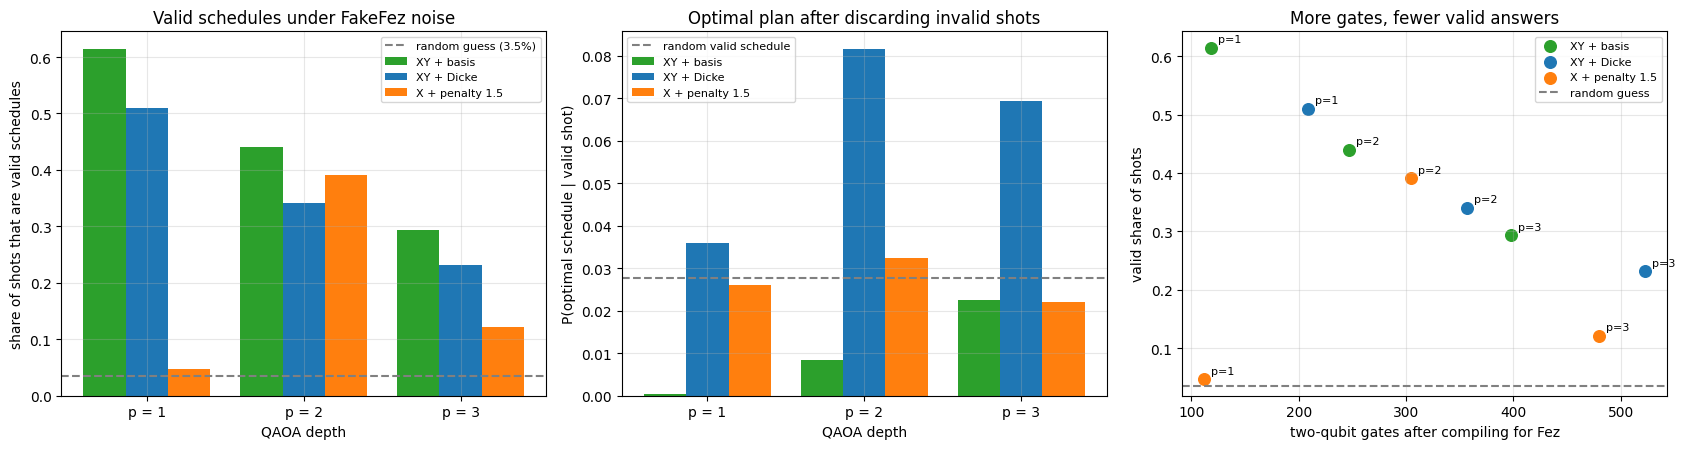

In [6]:
names = list(CONFIGS)
colors = dict(zip(names, ['tab:green', 'tab:blue', 'tab:orange']))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
w = 0.27
for i, name in enumerate(names):
    sub = [r for r in rows if r['config'] == name]
    xs = np.arange(len(REPS)) + (i - 1) * w
    axes[0].bar(xs, [r['valid_rate'] for r in sub], w, color=colors[name], label=name)
    axes[1].bar(xs, [r['p_optimal_postselected'] for r in sub], w, color=colors[name], label=name)
    axes[2].scatter([r['two_qubit_gates'] for r in sub], [r['valid_rate'] for r in sub],
                    color=colors[name], s=70, label=name)
    for r in sub:
        axes[2].annotate(f"p={r['p']}", (r['two_qubit_gates'], r['valid_rate']),
                         textcoords='offset points', xytext=(5, 4), fontsize=8)
for ax in axes[:2]:
    ax.set_xticks(range(len(REPS))); ax.set_xticklabels([f'p = {p}' for p in REPS])
    ax.set_xlabel('QAOA depth')
axes[0].axhline(RANDOM_VALID, ls='--', color='grey', label=f'random guess ({RANDOM_VALID:.1%})')
axes[0].set_ylabel('share of shots that are valid schedules'); axes[0].set_title('Valid schedules under FakeFez noise')
axes[1].axhline(base.n_optimal / base.n_valid, ls='--', color='grey', label='random valid schedule')
axes[1].set_ylabel('P(optimal schedule | valid shot)'); axes[1].set_title('Optimal plan after discarding invalid shots')
axes[2].axhline(RANDOM_VALID, ls='--', color='grey', label='random guess')
axes[2].set_xlabel('two-qubit gates after compiling for Fez'); axes[2].set_ylabel('valid share of shots')
axes[2].set_title('More gates, fewer valid answers')
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / 'noisy_overview.png', dpi=150); plt.show()

## Step 4 · Cheap fixes: discard invalid shots, correct measurement errors
We measure each qubit's readout error with two calibration circuits (all 0s, all 1s) on the same physical qubits, then undo those flips mathematically. We apply it to the depth-2 circuits.

XY + basis       valid 0.440 -> 0.465 after readout fix | P(opt) raw 0.004, readout-fixed 0.004, post-selected 0.008


XY + Dicke       valid 0.341 -> 0.356 after readout fix | P(opt) raw 0.028, readout-fixed 0.029, post-selected 0.082


X + penalty 1.5  valid 0.391 -> 0.408 after readout fix | P(opt) raw 0.013, readout-fixed 0.013, post-selected 0.032


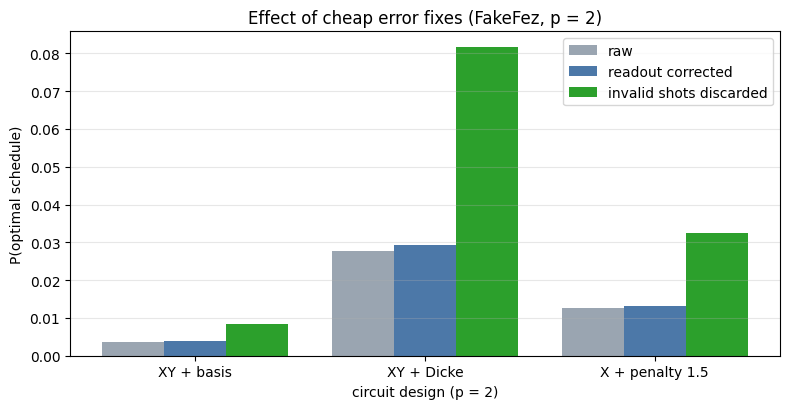

In [7]:
mit_rows = []
for name in names:
    tc, counts = compiled[name, 2], noisy[name, 2]
    rates = calibrate_readout(backend, noisy_sim, measured_physical_qubits(tc))
    fixed = correct_readout(counts, rates)
    raw, cor = score(counts, model, base), score(fixed, model, base)
    mit_rows.append(dict(config=name, raw_valid=raw['valid_rate'], corrected_valid=cor['valid_rate'],
                         raw_p_opt=raw['p_optimal'], corrected_p_opt=cor['p_optimal'],
                         postselected_p_opt=raw['p_optimal_valid']))
    print(f"{name:16s} valid {raw['valid_rate']:.3f} -> {cor['valid_rate']:.3f} after readout fix | "
          f"P(opt) raw {raw['p_optimal']:.3f}, readout-fixed {cor['p_optimal']:.3f}, post-selected {raw['p_optimal_valid']:.3f}")
json.dump(mit_rows, open(OUT / 'mitigation.json', 'w'), indent=2)
fig, ax = plt.subplots(figsize=(8, 4.2))
xs = np.arange(len(names))
ax.bar(xs - 0.27, [r['raw_p_opt'] for r in mit_rows], 0.27, label='raw', color='#9aa5b1')
ax.bar(xs, [r['corrected_p_opt'] for r in mit_rows], 0.27, label='readout corrected', color='#4c78a8')
ax.bar(xs + 0.27, [r['postselected_p_opt'] for r in mit_rows], 0.27, label='invalid shots discarded', color='#2ca02c')
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_xlabel('circuit design (p = 2)')
ax.set_ylabel('P(optimal schedule)'); ax.set_title('Effect of cheap error fixes (FakeFez, p = 2)')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / 'mitigation.png', dpi=150); plt.show()

## Step 5 · How much noise can each design tolerate?
A generic device where every two-qubit gate fails with probability *e* (single-qubit gates *e*/10). We sweep *e* for the depth-2 circuits.

XY + basis ['1.00', '0.91', '0.83', '0.63', '0.41', '0.19', '0.05']


XY + Dicke ['1.00', '0.89', '0.79', '0.59', '0.36', '0.17', '0.06']


X + penalty 1.5 ['0.78', '0.70', '0.66', '0.55', '0.40', '0.25', '0.09']


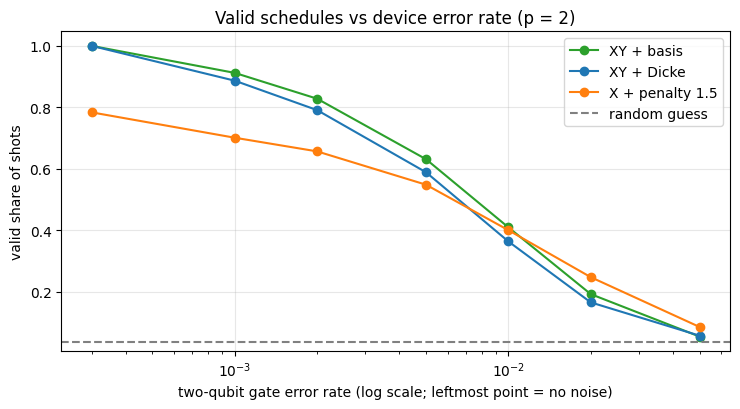

In [8]:
ERRS = [0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
sweep = {name: [] for name in names}
for name in names:
    tc = generic_transpile(circuits[name, 2], angles[name, 2])
    for e in ERRS:
        sim = AerSimulator(noise_model=depolarizing_model(e)) if e else AerSimulator()
        s = score(sample(tc, sim, 2048, seed=5), model, base)
        sweep[name].append(s['valid_rate'])
    print(name, [f'{v:.2f}' for v in sweep[name]])
json.dump(dict(two_qubit_error=ERRS, valid_rate=sweep), open(OUT / 'noise_sweep.json', 'w'), indent=2)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name in names:
    ax.plot([max(e, 3e-4) for e in ERRS], sweep[name], 'o-', color=colors[name], label=name)
ax.axhline(RANDOM_VALID, ls='--', color='grey', label='random guess')
ax.set_xscale('log'); ax.set_xlabel('two-qubit gate error rate (log scale; leftmost point = no noise)')
ax.set_ylabel('valid share of shots'); ax.set_title('Valid schedules vs device error rate (p = 2)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / 'noise_sweep.png', dpi=150); plt.show()

## Findings & limitations

All numbers come from the runs above (FakeFez noise, 4096 shots, fixed seeds). For reference, a random 12-bit guess is a valid schedule 3.5% of the time, and a random *valid* schedule is optimal 2.8% of the time (4 of 144).

- **Noise breaks the XY mixer's guarantee.** In perfect simulation the XY designs return 100% valid schedules. On FakeFez at p = 2 that drops to 44% (basis start) and 34% (Dicke start). Every design still beats random guessing by about 10×.
- **Depth hurts.** Each extra QAOA layer adds roughly 130–170 two-qubit gates after compiling for Fez, and the valid share falls with it: XY + basis goes 62% → 44% → 29% from p = 1 to 3.
- **Best design for real hardware: XY mixer + Dicke start at p = 2, keeping only valid shots.** After discarding invalid shots it picks the optimal plan 8.2% of the time, about 3× a random valid schedule. XY + basis is shallower and keeps more valid shots, but its p = 2 angles land on the optimum less often (0.8%).
- **The penalty design is fragile.** Even in perfect simulation its valid share swings between 4% (p = 1), 78% (p = 2) and 40% (p = 3), and its approximation ratio (0.67) is no better than a random valid schedule (0.66).
- **Cheap fixes help only a little.** Correcting measurement errors adds 1.5–2.5 points of valid share. Discarding invalid shots roughly triples P(optimal) for the XY designs.
- **Tolerance.** On a generic device the XY designs stay above 80% valid only while the two-qubit error rate is below about 0.2%; at 1% they fall to about 40%.

**Limitations.** FakeFez is a snapshot of one device's error rates, and real hardware usually behaves worse than its simulator. Angles were optimised without noise. We used one problem instance, one transpiler seed and 4096 shots per point. A run on real IBM hardware is the natural next step.